```{=latex}
\begin{center}
Wiputdanai Pinkaew 202624090101, Eugene Leong U Zii 202624090106 \\
School of Information and Software Engineering \\
University of Electronic Science and Technology of China
\end{center}
```

### Introduction
This report compares a traditional machine-learning pipeline with a deep-learning pipeline for image classification on CIFAR-10. The first pipeline flattens each image, reduces its dimensionality with Principal Component Analysis (PCA) and classifies it with a Support Vector Machine (SVM). The second pipeline fine-tunes a pretrained ResNet18 convolutional neural network (CNN). Both pipelines are evaluated on the same test images with the same metrics, so their results can be compared directly.

### Dataset and classes
This report uses the CIFAR-10 dataset, which contains 60,000 color images of 32x32 pixels in ten classes: `plane, car, bird, cat, deer, dog, frog, horse, ship, truck`. The official split provides 50,000 training images and 10,000 test images.

We thank you Arpit Rai for providing dataset via Mendeley Data. You can check out the dataset here: https://data.mendeley.com/datasets/kfjcsbhhss/1

### Structure of the report
The report is divided into three parts.

- Part A covers the PCA + SVM experiment (without ResNet): setup, data preparation, training and results
- Part B covers the ResNet18 experiment: setup, data preparation, training and results
- Part C compares the best result of Part A with the best result of Part B

Parts A and B are independent. Each has its own imports, configuration, data loading, train/validation split, helper functions and results, and neither uses any variable from the other. Part C requires the results of both. To keep the comparison fair, both parts use the same random seed and the same stratified train/validation split.

### Experiment A: Traditional machine learning (PCA + SVM)
Objectives:
1. Learn the application of traditional machine learning in image classification
2. Master the process of data flattening, dimensionality reduction (PCA) and classifier training (SVM)
3. Learn to analyze classification results, including the confusion matrix and the classification report

### Experiment B: ResNet18 deep learning
Objectives:
1. Understand the application of Convolutional Neural Networks (CNN) in image classification
2. Learn how to train, test and fine-tune a pre-defined model (ResNet18)
3. Master the visualization methods of training curve analysis, the confusion matrix and the classification report

### Evaluation
Both models are scored on the 10,000 test images using accuracy, macro-averaged precision, recall and F1-score, per-class metrics and confusion matrices. Part C summarizes the differences between the two approaches.

### Environment Settings
We use Windows x86_64 laptop with AMD Ryzen 7 7435HS CPU, 24GB of RAM, and NVIDIA Geforce RTX 4050 Laptop GPU to run the model. NVIDIA CUDA is utlized for performance, but also note that Apple's MPS is used as the experimentator use MacBook with Apple M1 CPU as well. All of the code are run under Python environment (`venv`) inside of Jupyter Notebook for dependencies control and easier debug reasons. And Python 3.12 is used for this experienment.

## 0. Dependencies install and model configurations

To install all of the dependencies, we use `requirements.txt` file to install specific Python libraries needed for this project, with fixed version to prevent dependency conflicts. You can install with command as follows.

```bash
pip install -r requirements.txt
```

In [1]:
import os, json, time, random, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

In [2]:
CLASSES = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
NUM_CLASSES = len(CLASSES)

SEED = 42
CIFAR_DIR = Path('cifar-10-batches-py')   # folder with data_batch_1..5, test_batch, batches.meta
VAL_RATIO = 0.1                           # held out from the 50k training images

---
# Experiment A: PCA + SVM

## A1. Setup

### A1.1) Imports

We import the `scikit-learn` library for PCA + SVM pipeline. `StandardScaler` standardizes every pixel feature to mean 0 and standard deviation 1, `PCA` reduces the 3072 flattened pixel values to a small number of principal components, and `SVC` trains the Support Vector Machine classifier with an RBF kernel.

In [3]:
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.1


### A1.2) Configuration

All settings that we may want to tune are placed in this cell. `N_TRAIN_SVM` is the number of training images used to train the final SVM. Since `RBF-SVM` becomes slow very quickly when the number of samples grows, we use 20000 so it finishes in a few minutes. `N_SWEEP` is a smaller subset that we use only for searching the best settings, so each trial is fast. `PCA_GRID` and `C_GRID` are the numbers of principal components (50, 100, 200) and the SVM regularization values (1, 10) that we want to try.

In [4]:
N_TRAIN_SVM = 20000      # None = use the whole training split
N_SWEEP = 10000          # smaller subset used only to pick (n_components, C)
PCA_GRID = [50, 100, 200]
C_GRID = [1, 10]

print('Classes:', CLASSES)

Classes: ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### A1.3) Reproducibility

Training results can change every time we run the notebook because of random numbers, so we fix the random seed first. The function `seed_everything` sets the seed for Python `random` and `numpy`, using the `SEED` value from the configuration. Since Part A does not use PyTorch, there is nothing else to seed here. This way, the train and validation split and the PCA result stay the same on every run.

In [5]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)

seed_everything(SEED)

## A2. Data manipulation

In this part, We load CIFAR-10 and prepare it for PCA + SVM. SVM cannot take an image directly, so each image has to be changed into one long vector of numbers first. After that, we normalize the numbers so PCA and SVM can work properly.

### A2.1) Load raw CIFAR-10

We use the original python version of CIFAR-10, which is the folder “cifar-10-batches-py”. Please make sure the folder is next to the notebook, or change `CIFAR_DIR` in the configuration. The folder contains five training batches with 10,000 images each, one test batch with 10,000 images, and the file “`batches.meta`” with the label names. Each batch is a pickle file, and the images are stored as one row of 3072 numbers (1024 red, 1024 green and 1024 blue values). So we reshape them back into 32x32x3 images and combine the five training batches into one array of 50,000 training images. Though the test batch is kept separate as 10,000 test images.

In [6]:
def load_batch(path):
    with open(path, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    # stored as (N, 3072) = 1024 R + 1024 G + 1024 B  ->  (N, 32, 32, 3)
    X = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b'labels'])
    return np.ascontiguousarray(X), y

assert CIFAR_DIR.is_dir(), 'Folder not found: %s (set CIFAR_DIR in the config cell)' % CIFAR_DIR

parts = [load_batch(CIFAR_DIR / ('data_batch_%d' % i)) for i in range(1, 6)]
X_all = np.concatenate([p[0] for p in parts])      # (50000, 32, 32, 3) uint8
y_all = np.concatenate([p[1] for p in parts])      # (50000,)
X_test_raw, y_test = load_batch(CIFAR_DIR / 'test_batch')   # (10000, 32, 32, 3), (10000,)

with open(CIFAR_DIR / 'batches.meta', 'rb') as f:
    meta = pickle.load(f, encoding='bytes')
print('Label names in batches.meta:', [n.decode() for n in meta[b'label_names']])

print('Train images:', X_all.shape, X_all.dtype)
print('Test images :', X_test_raw.shape)
print('Pixel range :', X_all.min(), '-', X_all.max())
print('Images per class (train):', np.bincount(y_all).tolist())

Label names in batches.meta: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train images: (50000, 32, 32, 3) uint8
Test images : (10000, 32, 32, 3)
Pixel range : 0 - 255
Images per class (train): [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]


### A2.2) Visual sanity-check

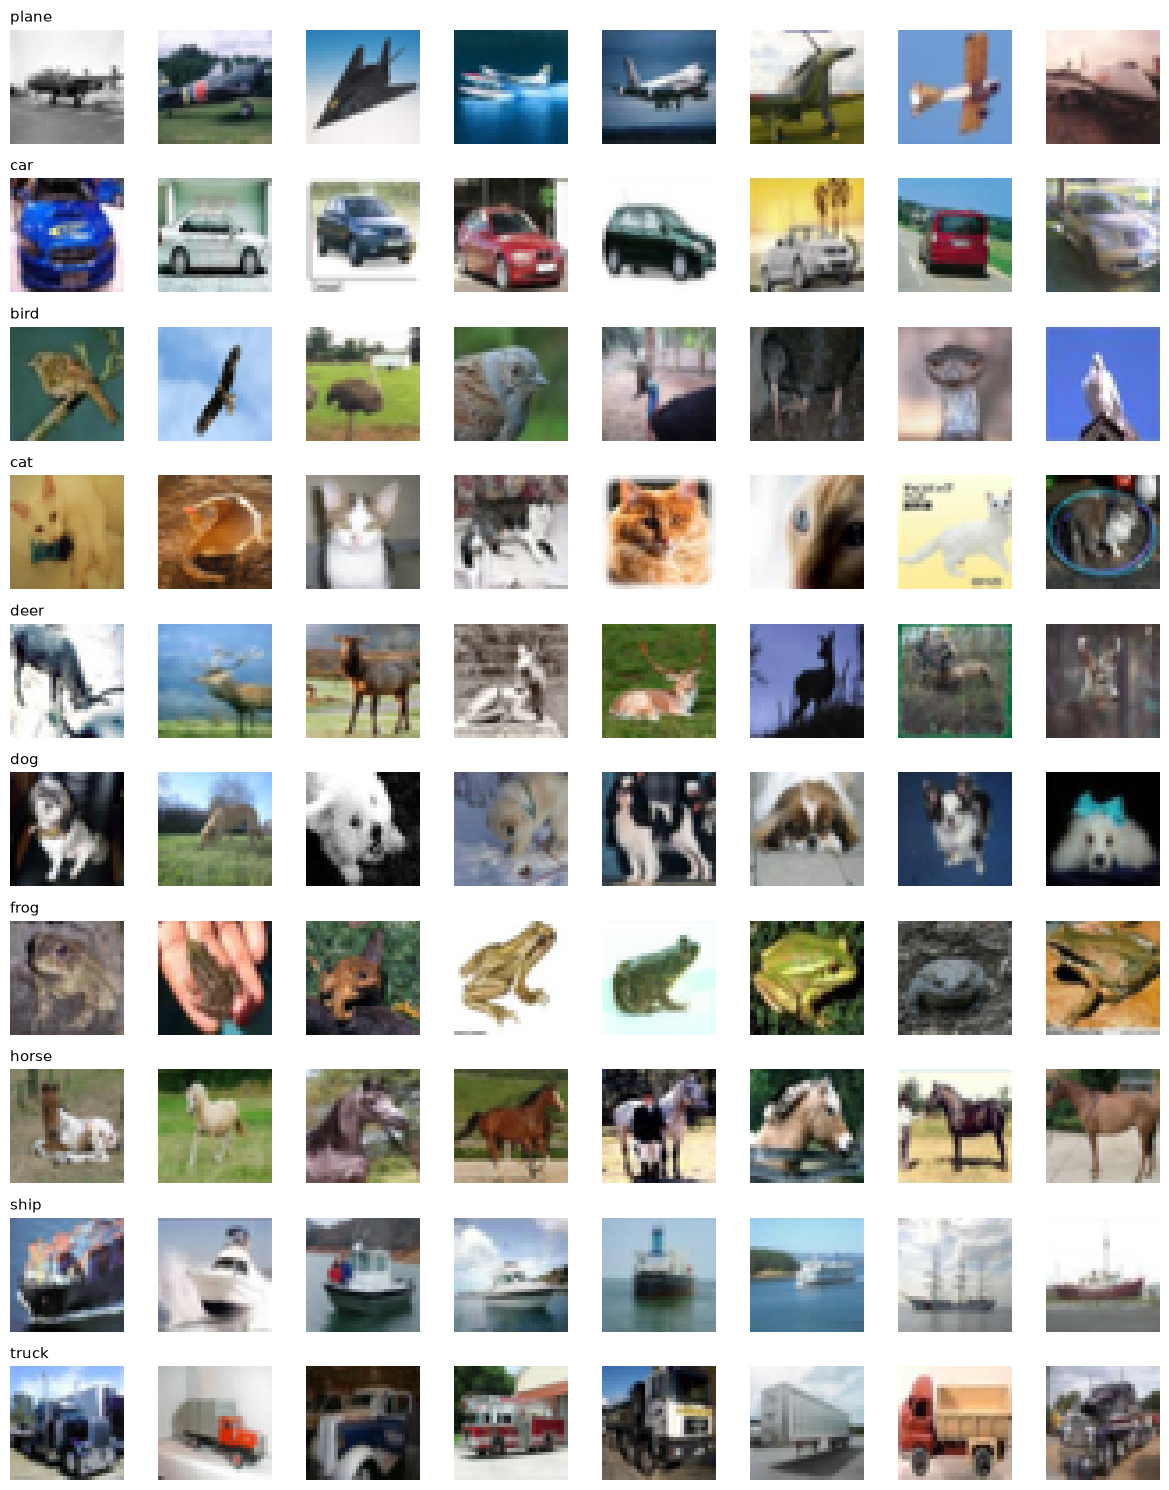

In [7]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(12, 15))
rng = np.random.RandomState(SEED)
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_all == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_all[i])
        axes[c, j].axis('off')
        if j == 0:
            axes[c, j].set_title(CLASSES[c], loc='left', fontsize=11)
plt.tight_layout()
plt.show()

### A2.3) Train / validation split (stratified)

We split the 50,000 training images into a training set and a validation set. The validation set is 10% (`VAL_RATIO`), so it is 45,000 images for training and 5,000 images for validation. I use a stratified split, which means every class keeps the same proportion in both sets. The validation set is used to choose the best PCA size and SVM setting. The 10,000 official test images are not touched until the final evaluation, so the test result is not biased by the tuning.

In [8]:
idx_train, idx_val = train_test_split(
    np.arange(len(y_all)), test_size=VAL_RATIO, stratify=y_all, random_state=SEED
)
print('train:', len(idx_train), '| val:', len(idx_val), '| test:', len(y_test))

y_train, y_val = y_all[idx_train], y_all[idx_val]

train: 45000 | val: 5000 | test: 10000


### A2.4) Normalization for PCA + SVM

There are three steps in this part.

**Step 1 is flatten**: each 32x32x3 image becomes one vector with length 3072.

**Step 2 is scale**: We divide the pixel values by 255, so they go from 0-255 to 0-1.

**Step 3 is standardize**: We use `StandardScaler()` to make each of the 3072 features have mean 0 and standard deviation 1.

We fit the scaler on the training images only, then apply it to the validation and test images. Standardizing is important here because PCA looks for the direction with the largest variance, and the RBF kernel of SVM depends on distance, so features with larger scale would dominate the result. Also, since `N_TRAIN_SVM` is set to 20000, only the first 20,000 images of the training split are used for this SVM.

In [9]:
def flatten01(X):
    return X.reshape(len(X), -1).astype(np.float32) / 255.0

# subset of the training split used for the SVM (idx_train is already shuffled)
idx_svm = idx_train if N_TRAIN_SVM is None else idx_train[:N_TRAIN_SVM]

X_svm_train = flatten01(X_all[idx_svm]);  y_svm_train = y_all[idx_svm]
X_val_flat = flatten01(X_all[idx_val])
X_test_flat = flatten01(X_test_raw)

print('Before scaling -> mean %.3f, std %.3f' % (X_svm_train.mean(), X_svm_train.std()))

scaler = StandardScaler().fit(X_svm_train)
X_svm_train = scaler.transform(X_svm_train)
X_val_flat = scaler.transform(X_val_flat)
X_test_flat = scaler.transform(X_test_flat)

print('After scaling  -> mean %.3f, std %.3f' % (X_svm_train.mean(), X_svm_train.std()))
print('SVM train:', X_svm_train.shape, '| val:', X_val_flat.shape, '| test:', X_test_flat.shape)

Before scaling -> mean 0.474, std 0.251
After scaling  -> mean -0.000, std 1.000
SVM train: (20000, 3072) | val: (5000, 3072) | test: (10000, 3072)


## A3. First train using PCA + SVM

In this part, we train the first model, which does not use any neural network.

The pipeline has four steps:
1. Flatten the image, standardize it
2. Reduce the dimension with PCA
3. Classify with SVM using the RBF kernel

A raw image gives 3072 features, and many of them are highly related to each other, for example the pixels next to each other usually have similar color. So, PCA keeps only the directions with the most variance, and the SVM can work in a much smaller space. This makes the training faster.

### A3.1) Fit PCA and inspect explained variance

Each CIFAR-10 image has 3,072 pixel values (32 × 32 × 3), and many of them are redundant because neighbouring pixels look alike (like sky or glass). To make the SVM faster and less noisy, we use PCA to compress each image into a much shorter list of numbers that keeps most of the information.

We fit PCA once on the training images, using 200 components. Smaller sizes (50 and 100) are just the first 50 or 100 components of the same result. Validation and test images are only transformed, not fitted, so they don’t leak into the training.

PCA fit: 4.4s
 50 components keep 83.9% of the variance
100 components keep 89.9% of the variance
200 components keep 94.5% of the variance


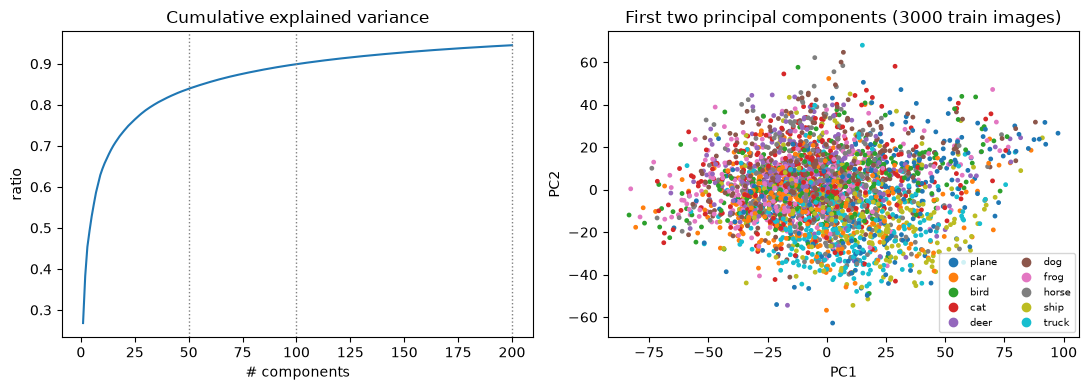

In [10]:
t0 = time.time()
pca = PCA(n_components=max(PCA_GRID), random_state=SEED).fit(X_svm_train)
print('PCA fit: %.1fs' % (time.time() - t0))

cum_var = np.cumsum(pca.explained_variance_ratio_)
for k in PCA_GRID:
    print('%3d components keep %.1f%% of the variance' % (k, 100 * cum_var[k - 1]))

# project everything once; smaller k is just a slice of the first k columns
Z_train_full = pca.transform(X_svm_train)
Z_val_full = pca.transform(X_val_flat)
Z_test_full = pca.transform(X_test_flat)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(cum_var) + 1), cum_var)
for k in PCA_GRID:
    ax[0].axvline(k, color='gray', ls=':', lw=1)
ax[0].set_title('Cumulative explained variance')
ax[0].set_xlabel('# components'); ax[0].set_ylabel('ratio')

sc = ax[1].scatter(Z_train_full[:3000, 0], Z_train_full[:3000, 1], c=y_svm_train[:3000], cmap='tab10', s=6)
ax[1].set_title('First two principal components (3000 train images)')
ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2')
ax[1].legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

To see how much information is kept, we print the percentage of variance for 50, 100 and 200 components. They keep 83.9%, 89.9% and 94.5% of the variance. We also plot the cumulative explained variance, with a dotted line at each value of `PCA_GRID`. The curve goes up fast in the beginning and gets flat after around 50 components, so going from 100 to 200 components only adds about 4.6% more information.

With 200 components, the input shrinks from 3,072 to 200 features while still keeping 94.5% of the variance. More components keep more information, but with diminishing returns.

We also plot the first two principal components of 3000 training images, colored by class. This plot is only for us to look at the data in 2D. The classes overlap a lot, because two components are far too few to separate ten classes. So we still need more components and a classifier to separate them.

### A3.2) Pick the PCA size and SVM `C` on the validation set

In a Support Vector Machine (SVM), the parameter C controls how strongly the model is penalised for misclassifying training points. It balances two goals: keeping the decision boundary smooth and simple, and classifying every training point correctly.

- A small C makes mistakes cheap. The SVM tolerates some training errors and produces a smoother boundary. If C is too small, the model may be too simple to capture real patterns (underfitting).
- A large C makes mistakes expensive. The SVM tries to classify every training point correctly, which produces a more complex boundary. If C is too large, the model may memorise noise in the training data and perform worse on new images (overfitting).

Since the best level of strictness is not known in advance, C is treated as a hyperparameter and tuned on the validation set. We compared C = 1 and C = 10 and kept the value that gave the higher validation accuracy.

In our experiments, changing C from 1 to 10 made very little difference. For example, with 100 PCA components, accuracy was 47.60% at C = 1 and 46.98% at C = 10. The slightly lower score at the larger C may be a mild sign of overfitting, but the gap is small. This suggests that on this data, the number of PCA components affects accuracy more than the choice of C.

In [11]:
n_sweep = min(N_SWEEP, len(Z_train_full))
rows = []
for k in PCA_GRID:
    for C in C_GRID:
        t0 = time.time()
        clf = SVC(kernel='rbf', C=C, gamma='scale')
        clf.fit(Z_train_full[:n_sweep, :k], y_svm_train[:n_sweep])
        val_acc = clf.score(Z_val_full[:, :k], y_val)
        rows.append({'n_components': k, 'C': C, 'val_acc': val_acc, 'seconds': time.time() - t0})
        print('k=%3d  C=%-4s  val acc %.4f  (%.1fs)' % (k, C, val_acc, time.time() - t0))

sweep_df = pd.DataFrame(rows).sort_values('val_acc', ascending=False).reset_index(drop=True)
best_k = int(sweep_df.loc[0, 'n_components'])
best_C = float(sweep_df.loc[0, 'C'])
print('\nBest setting -> n_components=%d, C=%s' % (best_k, best_C))
sweep_df

k= 50  C=1     val acc 0.4578  (12.7s)
k= 50  C=10    val acc 0.4530  (9.2s)
k=100  C=1     val acc 0.4760  (8.2s)
k=100  C=10    val acc 0.4698  (9.6s)
k=200  C=1     val acc 0.4738  (12.3s)
k=200  C=10    val acc 0.4750  (15.4s)

Best setting -> n_components=100, C=1.0


,n_components,C,val_acc,seconds
0,100,1,0.4760,8.192856
1,200,10,0.4750,15.401628
2,200,1,0.4738,12.347119
3,100,10,0.4698,9.616009
4,50,1,0.4578,12.713773
5,50,10,0.4530,9.204309


### A3.3) Train the final SVM

With the best setting, we train the final SVM again. This time we use all of the images in the SVM training subset instead of the smaller sweep subset, since more data should give a better model. We record the training time, because we will use it in the comparison with ResNet18 in Part C. Finally, we predict the labels of the 10,000 test images and keep them in `svm_pred`.

In [12]:
t0 = time.time()
svm = SVC(kernel='rbf', C=best_C, gamma='scale')
svm.fit(Z_train_full[:, :best_k], y_svm_train)
svm_train_time = time.time() - t0

svm_val_acc = svm.score(Z_val_full[:, :best_k], y_val)
print('Final SVM trained on %d images in %.1fs' % (len(y_svm_train), svm_train_time))
print('Validation accuracy: %.4f' % svm_val_acc)

# predictions on the held-out test set (evaluated in section A4)
svm_pred = svm.predict(Z_test_full[:, :best_k])

Final SVM trained on 20000 images in 24.0s
Validation accuracy: 0.5002


## A4. Results (PCA + SVM)

In this part, we evaluate the final SVM on the 10,000 test images, which were not used for training or for choosing the setting. We use accuracy (share of images classified correctly), precision (of the images predicted as class c, how many really are c), recall (of the images that really are class c, how many were found), F1 (the balance between precision and recall) and the confusion matrix (which classes get mixed up with which).

### A4.1) Evaluation helpers

In [13]:
def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)),
            'precision_macro': float(p), 'recall_macro': float(r), 'f1_macro': float(f)}

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support': s}, index=CLASSES)

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, data, sub, fmt in [(axes[0], cm, 'counts', 'd'), (axes[1], cm_norm, 'row-normalized', '.2f')]:
        ax.imshow(data, interpolation='nearest', cmap='Blues')
        ax.set_title(title + ' (' + sub + ')')
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        thresh = data.max() / 2
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(data[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if data[i, j] > thresh else 'black')
    plt.tight_layout()
    plt.show()
    return cm

def show_misclassified(y_true, y_pred, n=12):
    wrong = np.where(y_true != y_pred)[0]
    pick = np.random.RandomState(SEED).choice(wrong, min(n, len(wrong)), replace=False)
    plt.figure(figsize=(12, 2.4 * ((len(pick) + 5) // 6)))
    for k, i in enumerate(pick):
        plt.subplot((len(pick) + 5) // 6, 6, k + 1)
        plt.imshow(X_test_raw[i])
        plt.title('true: %s\npred: %s' % (CLASSES[y_true[i]], CLASSES[y_pred[i]]), fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

### A4.2) Overall metrics + classification report

In [14]:
svm_metrics = compute_metrics(y_test, svm_pred)

print('PCA(%d) + SVM(C=%s) on the test set' % (best_k, best_C))
for k, v in svm_metrics.items():
    print('  %-16s %.4f' % (k, v))

print()
print(classification_report(y_test, svm_pred, target_names=CLASSES, digits=4))

PCA(100) + SVM(C=1.0) on the test set
  accuracy         0.4994
  precision_macro  0.4980
  recall_macro     0.4994
  f1_macro         0.4975

              precision    recall  f1-score   support

       plane     0.5821    0.5780    0.5800      1000
         car     0.6095    0.6010    0.6052      1000
        bird     0.3726    0.3540    0.3631      1000
         cat     0.3440    0.3330    0.3384      1000
        deer     0.4267    0.4220    0.4243      1000
         dog     0.4461    0.3970    0.4201      1000
        frog     0.4927    0.6060    0.5435      1000
       horse     0.5776    0.4950    0.5331      1000
        ship     0.5808    0.6470    0.6121      1000
       truck     0.5484    0.5610    0.5546      1000

    accuracy                         0.4994     10000
   macro avg     0.4980    0.4994    0.4975     10000
weighted avg     0.4980    0.4994    0.4975     10000



The model is PCA with 100 components and SVM with C = 1. It gets a test accuracy of 49.94%. The macro-averaged precision, recall and F1 are 0.4980, 0.4994 and 0.4975 respectively. The classification report shows the same metrics for each class. Ship has the highest F1 (0.6121), followed closely by car (0.6052), and cat has the lowest (0.3384), followed by bird (0.3631). The vehicles are easier for this model, while the animals are harder, especially cat, bird and dog.

### A4.3) Confusion matrix

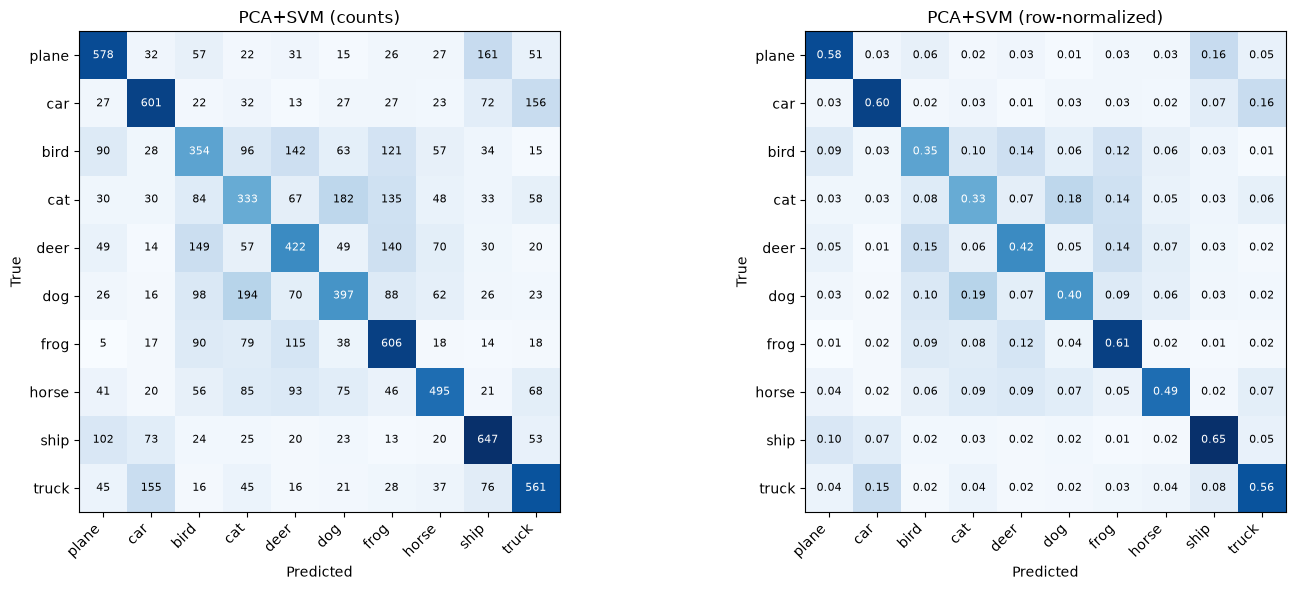

In [15]:
cm_svm = plot_confusion(y_test, svm_pred, 'PCA+SVM')

The confusion matrix is shown as counts and as row-normalized ratios. The diagonal is the correct predictions, and the other cells are the mistakes. The model is best at ship (647 correct, 65%), frog (606), car (601) and plane (578), and worst at cat (333, 33%) and bird (354, 35%). The main confusions are between similar classes. Cat and dog are mixed with each other the most (194 dogs predicted as cat, 182 cats predicted as dog). Car and truck are also mixed (156 cars predicted as truck, 155 trucks predicted as car). In addition, 161 planes are predicted as ship, probably because both often have a blue background of sky or sea. Many animal classes (bird, cat, deer) are also predicted as frog, which shows that the model cannot separate animals well from raw pixels.

### A4.4) Per-class metrics and most-confused pairs

,precision,recall,f1,support
plane,0.5821,0.578,0.5800,1000
car,0.6095,0.601,0.6052,1000
bird,0.3726,0.354,0.3631,1000
cat,0.3440,0.333,0.3384,1000
deer,0.4267,0.422,0.4243,1000
dog,0.4461,0.397,0.4201,1000
frog,0.4927,0.606,0.5435,1000
horse,0.5776,0.495,0.5331,1000
ship,0.5808,0.647,0.6121,1000
truck,0.5484,0.561,0.5546,1000


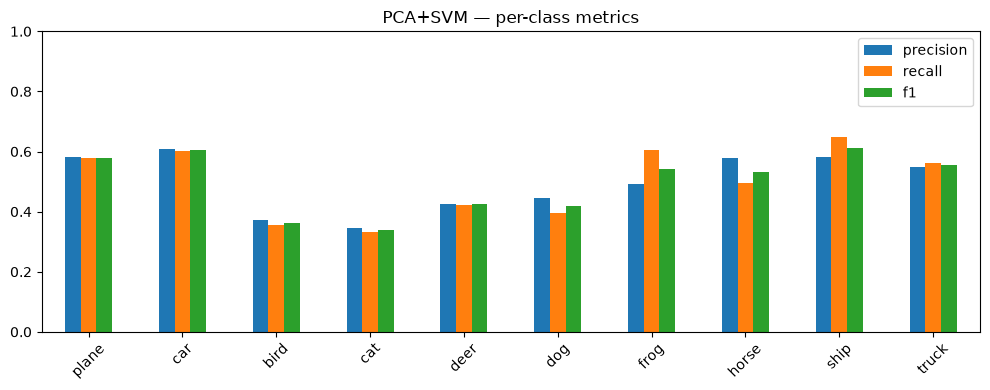

Most confused pairs (true -> predicted):
  dog    -> cat    : 194 images
  cat    -> dog    : 182 images
  plane  -> ship   : 161 images
  car    -> truck  : 156 images
  truck  -> car    : 155 images


In [16]:
svm_pc = per_class_table(y_test, svm_pred)
display(svm_pc.round(4))

svm_pc[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 4), title='PCA+SVM — per-class metrics')
plt.ylim(0, 1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

off = cm_svm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print('Most confused pairs (true -> predicted):')
for i, j in top:
    print('  %-6s -> %-6s : %d images' % (CLASSES[i], CLASSES[j], off[i, j]))

We plot the precision, recall and F1 of each class in a bar chart, and print the five most confused pairs (true class to predicted class). The most confused pair is dog to cat, with 194 images, followed by cat to dog (182), plane to ship (161), car to truck (156) and truck to car (155). All five pairs are similar-looking classes, and cat and dog appear twice.

In the per-class table, ship (F1 0.6121), car (0.6052) and truck (0.5546) are among the best, and cat (0.3384) and bird (0.3631) are the worst. Frog has a higher recall (0.606) than precision (0.4927), because the model predicts frog too often for other animals, while horse is the opposite (precision 0.5776, recall 0.495).

### A4.5) Misclassified examples

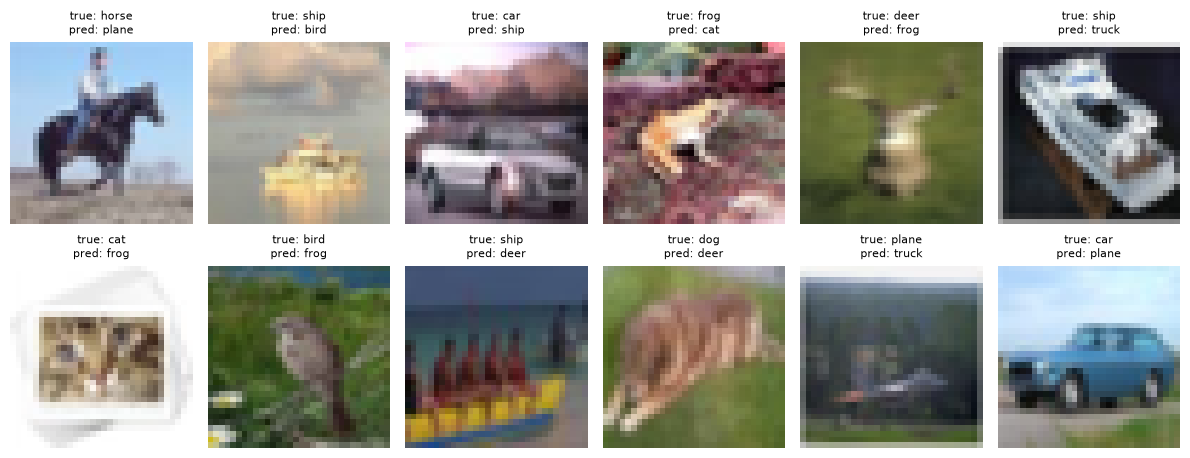

In [17]:
show_misclassified(y_test, svm_pred)

### A4.6) Package the Part A result

Finally, we put the metrics, per-class table, predictions and training time into one variable, svm_result. Part C will read this variable from Part A.

In [18]:
svm_result = {
    'detail': 'PCA(%d) + RBF-SVM(C=%s)' % (best_k, best_C),
    'train_time_s': float(svm_train_time),
    'metrics': svm_metrics,
    'per_class': svm_pc,
    'y_true': np.array(y_test),
    'y_pred': np.array(svm_pred),
}
print('Part A done:', svm_result['detail'], '| test accuracy %.4f' % svm_metrics['accuracy'])

Part A done: PCA(100) + RBF-SVM(C=1.0) | test accuracy 0.4994


---
# PART B — ResNet18 (deep learning)

Sections:
- B1. Setup
- B2. Data manipulation
- B3. Second train with ResNet18
- B4. Results.

Part B starts from scratch: it re-imports, re-loads the data and re-creates the split. It does not use anything from Part A.

## B1. Setup

### B1.1) Imports

Part B needs `torch` and `torchvision` (plus `numpy`, `pandas`, `matplotlib`, `pillow` and `scikit-learn` for the split and the metrics). It does not use PCA or SVM.

In [19]:
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models



warnings.filterwarnings('ignore')
print('torch:', torch.__version__)
print('torchvision:', __import__('torchvision').__version__)

torch: 2.14.0+cu130
torchvision: 0.29.0+cu130


### B1.2) Device

We use `cuda` if available, else `mps` (Apple Silicon), else `cpu`.

In [20]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

device = get_device()
device

device(type='cuda')

### B1.3) Configuration

Everything we want to tune is in here.

- `IMG_SIZE`: CIFAR images are 32x32. Upscaling helps the ImageNet-pretrained ResNet18 (`224` is the most accurate but slowest; `64`-`128` is a good trade-off).
- `SEED` and `VAL_RATIO` must match the same two values in Part A so both use the identical split.

In [21]:
OUT_DIR = Path('models')                  # model weights + class names
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- ResNet18 ---
USE_PRETRAINED = True    # ImageNet weights
IMG_SIZE = 128
BATCH = 128
NUM_WORKERS = 0
EPOCHS_1 = 3             # phase 1: train the new head only
EPOCHS_2 = 7             # phase 2: fine-tune the whole network
LR_HEAD = 1e-3
LR_FT = 1e-4

print('Device:', device)
print('Classes:', CLASSES)

Device: cuda
Classes: ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


### B1.4) Reproducibility

In [22]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

## B2. Data manipulation

We load CIFAR-10 and prepare it for ResNet18:

| Pipeline | Input | Normalization |
|---|---|---|
| ResNet18 | image tensor `[3, H, W]` | scale to [0, 1], then ImageNet mean / std (what the pretrained weights expect) |

### B2.1) Load raw CIFAR-10

In [23]:
def load_batch(path):
    with open(path, 'rb') as f:
        d = pickle.load(f, encoding='bytes')
    # stored as (N, 3072) = 1024 R + 1024 G + 1024 B  ->  (N, 32, 32, 3)
    X = d[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b'labels'])
    return np.ascontiguousarray(X), y

assert CIFAR_DIR.is_dir(), 'Folder not found: %s (set CIFAR_DIR in the config cell)' % CIFAR_DIR

parts = [load_batch(CIFAR_DIR / ('data_batch_%d' % i)) for i in range(1, 6)]
X_all = np.concatenate([p[0] for p in parts])      # (50000, 32, 32, 3) uint8
y_all = np.concatenate([p[1] for p in parts])      # (50000,)
X_test_raw, y_test = load_batch(CIFAR_DIR / 'test_batch')   # (10000, 32, 32, 3), (10000,)

with open(CIFAR_DIR / 'batches.meta', 'rb') as f:
    meta = pickle.load(f, encoding='bytes')
print('Label names in batches.meta:', [n.decode() for n in meta[b'label_names']])

print('Train images:', X_all.shape, X_all.dtype)
print('Test images :', X_test_raw.shape)
print('Pixel range :', X_all.min(), '-', X_all.max())
print('Images per class (train):', np.bincount(y_all).tolist())

Label names in batches.meta: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train images: (50000, 32, 32, 3) uint8
Test images : (10000, 32, 32, 3)
Pixel range : 0 - 255
Images per class (train): [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]


### B2.2) Visual sanity-check

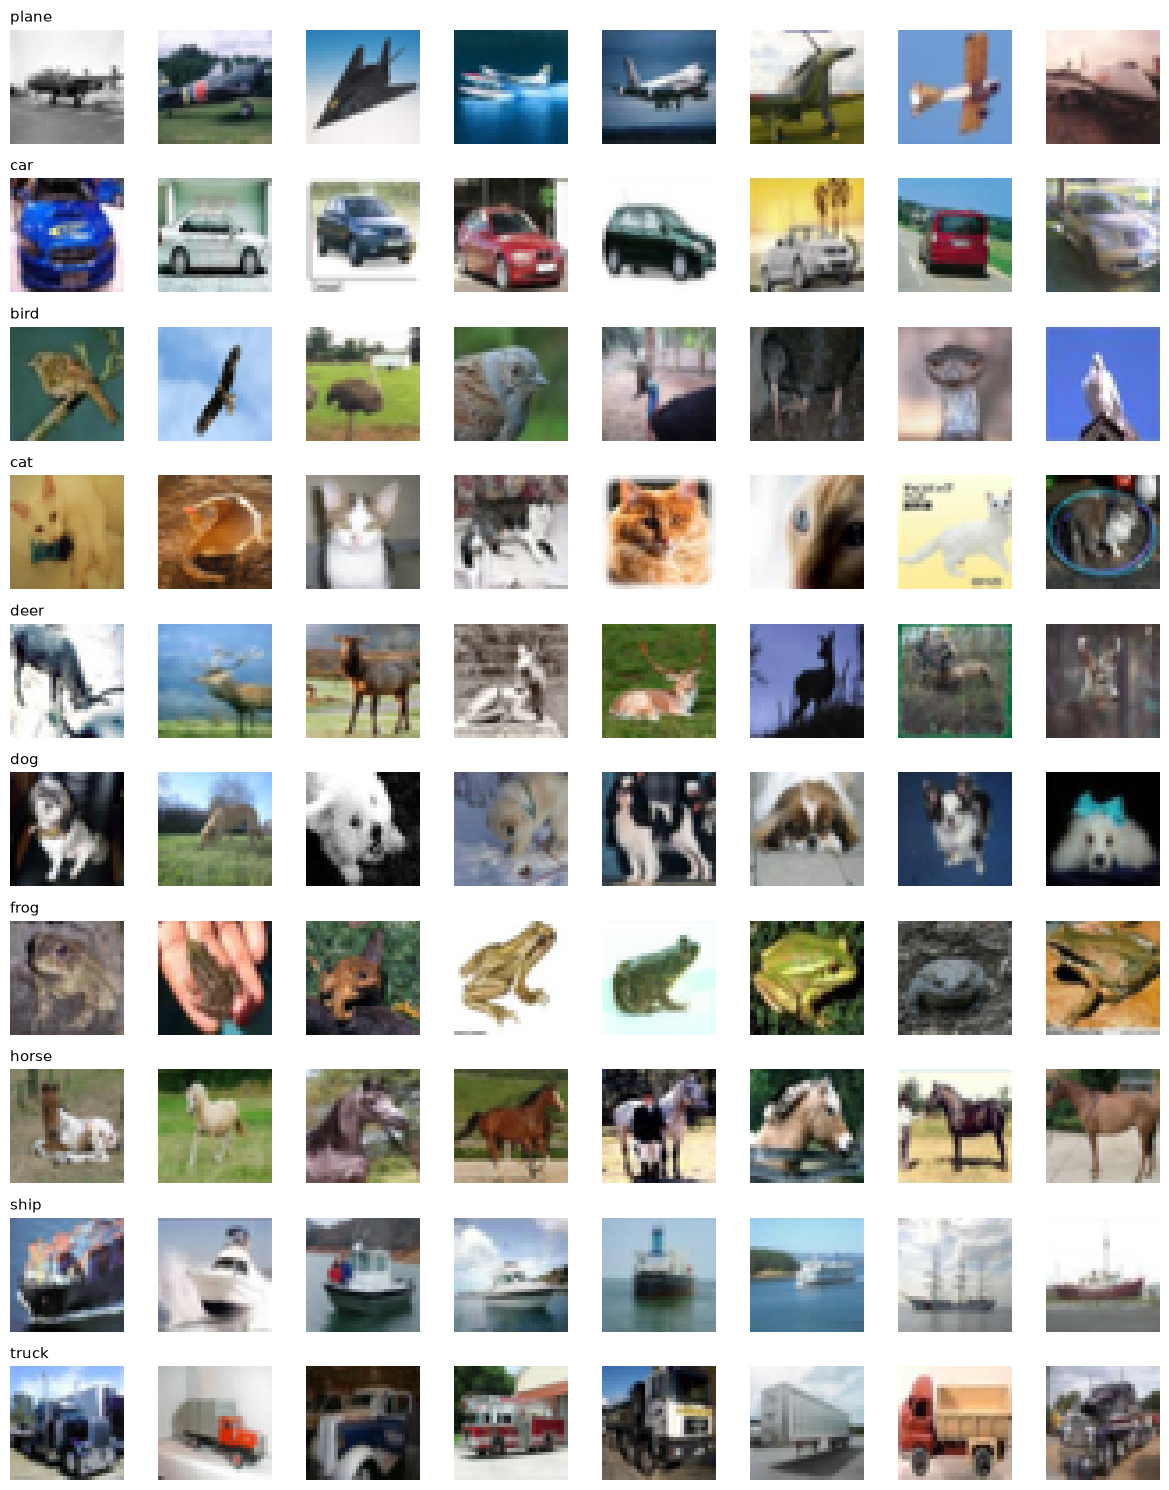

In [24]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(12, 15))
rng = np.random.RandomState(SEED)
for c in range(NUM_CLASSES):
    idx = rng.choice(np.where(y_all == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_all[i])
        axes[c, j].axis('off')
        if j == 0:
            axes[c, j].set_title(CLASSES[c], loc='left', fontsize=11)
plt.tight_layout()
plt.show()

### B2.3) Train / validation split (stratified)

The validation set is used to choose the best ResNet checkpoint. The 10,000 official test images are touched only for the final evaluation.

In [25]:
idx_train, idx_val = train_test_split(
    np.arange(len(y_all)), test_size=VAL_RATIO, stratify=y_all, random_state=SEED
)
print('train:', len(idx_train), '| val:', len(idx_val), '| test:', len(y_test))

y_train, y_val = y_all[idx_train], y_all[idx_val]

train: 45000 | val: 5000 | test: 10000


### B2.4) Normalization + augmentation for ResNet18

The ImageNet-pretrained weights expect:
- mean = (0.485, 0.456, 0.406)
- std  = (0.229, 0.224, 0.225)

Training images get light augmentation (random crop with padding + horizontal flip). Validation / test images are only resized and normalized.

In [26]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_tfms = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class CifarArrayDataset(Dataset):
    # wraps the uint8 arrays loaded from cifar-10-batches-py
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = X, y, transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = Image.fromarray(self.X[i])
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.y[i])

train_ds = CifarArrayDataset(X_all[idx_train], y_all[idx_train], train_tfms)   # with augmentation
val_ds = CifarArrayDataset(X_all[idx_val], y_all[idx_val], eval_tfms)          # no augmentation
test_ds = CifarArrayDataset(X_test_raw, y_test, eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)

print('ResNet train / val / test:', len(train_ds), len(val_ds), len(test_ds))

ResNet train / val / test: 45000 5000 10000


Batch tensor: (128, 3, 128, 128) | mean -0.17, std 1.18


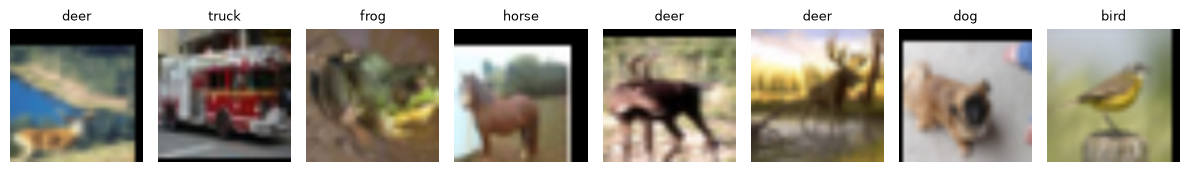

In [27]:
def denorm(img_t):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return torch.clamp(img_t.cpu() * std + mean, 0, 1)

images, labels = next(iter(train_loader))
print('Batch tensor:', tuple(images.shape), '| mean %.2f, std %.2f' % (images.mean(), images.std()))

plt.figure(figsize=(12, 3.5))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(denorm(images[i]).permute(1, 2, 0))
    plt.title(CLASSES[labels[i].item()], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## B3. Second train with ResNet18

We use **transfer learning** with a ResNet18 pretrained on ImageNet:

- **Phase 1** — freeze the backbone, train only the new final layer (`fc`, 10 outputs).
- **Phase 2** — unfreeze everything and fine-tune with a lower learning rate and a cosine schedule.

The checkpoint with the best **validation** accuracy across both phases is kept.

### B3.1) Build the model

In [28]:
seed_everything(SEED)

def build_resnet18(num_classes, pretrained=True):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, num_classes)   # new head for 10 classes
    return m

model = build_resnet18(NUM_CLASSES, USE_PRETRAINED).to(device)

total_params = sum(p.numel() for p in model.parameters())
print('ResNet18 parameters: %.2fM' % (total_params / 1e6))
print('Final layer:', model.fc)

ResNet18 parameters: 11.18M
Final layer: Linear(in_features=512, out_features=10, bias=True)


### B3.2) Training utilities

In [29]:
criterion = nn.CrossEntropyLoss()
history = []                       # one dict per epoch (both phases)
best_val_acc = 0.0
BEST_PATH = OUT_DIR / 'resnet18_best.pt'

def run_epoch(model, loader, criterion, optimizer=None, freeze_bn=False):
    training = optimizer is not None
    model.train(training)
    if training and freeze_bn:     # keep BatchNorm statistics of the frozen backbone
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

def run_phase(name, epochs, optimizer, scheduler=None, freeze_bn=False):
    global best_val_acc
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, freeze_bn)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if scheduler is not None:
            scheduler.step()
        history.append({'phase': name, 'epoch': len(history) + 1, 'train_loss': tr_loss,
                        'train_acc': tr_acc, 'val_loss': va_loss, 'val_acc': va_acc})
        flag = ''
        if va_acc > best_val_acc:
            best_val_acc = va_acc
            torch.save(model.state_dict(), BEST_PATH)
            flag = '  <- best'
        print('[%s][%d/%d] train loss %.4f acc %.4f | val loss %.4f acc %.4f | %.1fs%s' %
              (name, epoch, epochs, tr_loss, tr_acc, va_loss, va_acc, time.time() - t0, flag))

### B3.3) Phase 1: train the head (backbone frozen)

In [30]:
resnet_t0 = time.time()

for name, p in model.named_parameters():
    p.requires_grad = name.startswith('fc.')

opt1 = optim.Adam([p for p in model.parameters() if p.requires_grad], lr=LR_HEAD)
run_phase('Phase1', EPOCHS_1, opt1, freeze_bn=True)
print('Best val acc so far: %.4f' % best_val_acc)

[Phase1][1/3] train loss 0.7502 acc 0.7549 | val loss 0.5043 acc 0.8248 | 37.3s  <- best
[Phase1][2/3] train loss 0.5355 acc 0.8186 | val loss 0.4811 acc 0.8392 | 36.8s  <- best
[Phase1][3/3] train loss 0.5097 acc 0.8246 | val loss 0.4720 acc 0.8418 | 37.2s  <- best
Best val acc so far: 0.8418


### B3.4) Phase 2: fine-tune the whole network

In [31]:
for p in model.parameters():
    p.requires_grad = True

opt2 = optim.AdamW(model.parameters(), lr=LR_FT, weight_decay=1e-4)
sched2 = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=EPOCHS_2)
run_phase('Phase2', EPOCHS_2, opt2, scheduler=sched2)

resnet_train_time = time.time() - resnet_t0
print('Best val acc (final): %.4f | total training time: %.1f min' % (best_val_acc, resnet_train_time / 60))

[Phase2][1/7] train loss 0.3376 acc 0.8854 | val loss 0.2074 acc 0.9256 | 65.4s  <- best
[Phase2][2/7] train loss 0.1755 acc 0.9391 | val loss 0.1813 acc 0.9374 | 66.0s  <- best
[Phase2][3/7] train loss 0.1172 acc 0.9602 | val loss 0.1710 acc 0.9444 | 66.6s  <- best
[Phase2][4/7] train loss 0.0840 acc 0.9707 | val loss 0.1662 acc 0.9470 | 65.9s  <- best
[Phase2][5/7] train loss 0.0543 acc 0.9815 | val loss 0.1476 acc 0.9506 | 65.9s  <- best
[Phase2][6/7] train loss 0.0416 acc 0.9867 | val loss 0.1353 acc 0.9558 | 66.0s  <- best
[Phase2][7/7] train loss 0.0330 acc 0.9901 | val loss 0.1326 acc 0.9566 | 65.1s  <- best
Best val acc (final): 0.9566 | total training time: 9.5 min


## B4. Results (ResNet18)

### B4.1) Evaluation helpers

Part A defines the same helpers on its own, so both models are scored identically.

In [32]:
def compute_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y_true, y_pred)),
            'precision_macro': float(p), 'recall_macro': float(r), 'f1_macro': float(f)}

def per_class_table(y_true, y_pred):
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f, 'support': s}, index=CLASSES)

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, data, sub, fmt in [(axes[0], cm, 'counts', 'd'), (axes[1], cm_norm, 'row-normalized', '.2f')]:
        ax.imshow(data, interpolation='nearest', cmap='Blues')
        ax.set_title(title + ' (' + sub + ')')
        ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
        ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        thresh = data.max() / 2
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                ax.text(j, i, format(data[i, j], fmt), ha='center', va='center', fontsize=8,
                        color='white' if data[i, j] > thresh else 'black')
    plt.tight_layout()
    plt.show()
    return cm

def show_misclassified(y_true, y_pred, n=12):
    wrong = np.where(y_true != y_pred)[0]
    pick = np.random.RandomState(SEED).choice(wrong, min(n, len(wrong)), replace=False)
    plt.figure(figsize=(12, 2.4 * ((len(pick) + 5) // 6)))
    for k, i in enumerate(pick):
        plt.subplot((len(pick) + 5) // 6, 6, k + 1)
        plt.imshow(X_test_raw[i])
        plt.title('true: %s\npred: %s' % (CLASSES[y_true[i]], CLASSES[y_pred[i]]), fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

### B4.2) Training curves

Throughout the experiment, for the Accuracy part, both `train_acc` and `val_acc` increased from 0.7549 to 0.9901 and 0.8248 to 0.9566 respectively; meanwhile, for the Loss part, both `train_loss` and `val_loss` decreased from 0.7502 to 0.0330 and from 0.5043 to 0.1326 respectively.

Both `train_acc` and `val_acc` experienced a jump in accuracy during the transition from Phase 1 to Phase 2, which corresponds with the sharp drop in `train_loss` and `val_loss`. This is due to in Phase 1, only the linear classification head is trained on fixed pre-trained features, thus it can only find the best linear separation of features that were optimised for ImageNet rather than this dataset; therefore, both accuracy and loss plateaued quickly at the end of Phase 1. Upon transitioning to Phase 2, layer 4 is unfrozen. Thus, making roughly 8 million pre-trained parameters trainable, thus the high-level features can now adapt to the target classes, raising the achievable accuracy and lowering the loss.

From epoch 5 onwards, both train and val metrics intersect, and `train_acc` remained higher than `val_acc`, while `val_loss` remained higher than `train_loss` at the end of the training session. The model gained lots of trainable capacity post-unfreezing, thus `train_acc` rises quickly, catching up with `val_acc`. The model then starts to fit train-specific details, which explains the continuous improvement in train metrics while val metrics slow down. This indicates a mild overfitting of the model. Nonetheless, the overfitting is tame since val metrics are stable at the late stages of training rather than rebounding. The model simply hit its generalization ceiling.

,phase,epoch,train_loss,train_acc,val_loss,val_acc
0,Phase1,1,0.7502,0.7549,0.5043,0.8248
1,Phase1,2,0.5355,0.8186,0.4811,0.8392
2,Phase1,3,0.5097,0.8246,0.4720,0.8418
3,Phase2,4,0.3376,0.8854,0.2074,0.9256
4,Phase2,5,0.1755,0.9391,0.1813,0.9374
5,Phase2,6,0.1172,0.9602,0.1710,0.9444
6,Phase2,7,0.0840,0.9707,0.1662,0.9470
7,Phase2,8,0.0543,0.9815,0.1476,0.9506
8,Phase2,9,0.0416,0.9867,0.1353,0.9558
9,Phase2,10,0.0330,0.9901,0.1326,0.9566


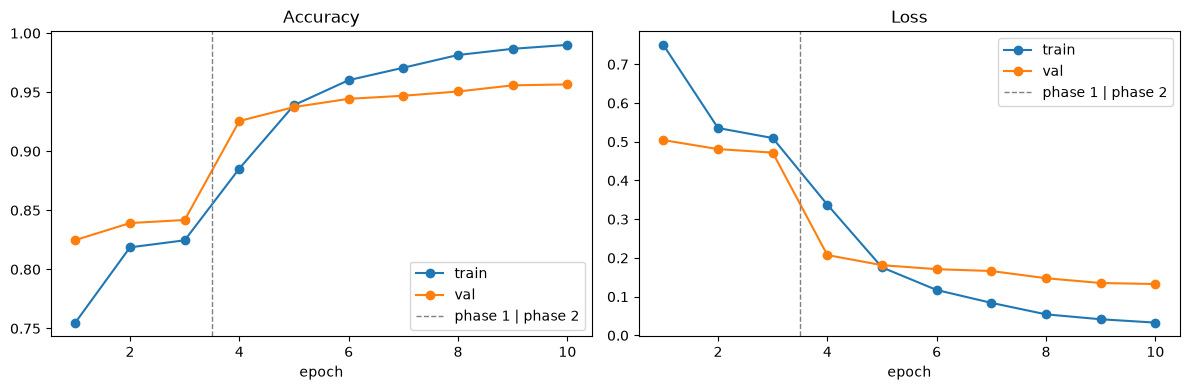

In [33]:
hist = pd.DataFrame(history)
display(hist.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (tr, va, title) in zip(ax, [('train_acc', 'val_acc', 'Accuracy'), ('train_loss', 'val_loss', 'Loss')]):
    a.plot(hist['epoch'], hist[tr], marker='o', label='train')
    a.plot(hist['epoch'], hist[va], marker='o', label='val')
    a.axvline(EPOCHS_1 + 0.5, color='gray', ls='--', lw=1, label='phase 1 | phase 2')
    a.set_title(title); a.set_xlabel('epoch'); a.legend()
plt.tight_layout()
plt.show()

### B4.3) Test evaluation with the best checkpoint

The following section describes the evaluation of the per-class metrics. Overall, the model's classification accuracy is very satisfactory across all classes, with nearly all classes having a f1-score of around 95%. However, `cat` and `dog` have the lowest f1-scores (0.9009 and 0.9135 respectively). Specifically, `cat` has a recall of 0.8860 and `dog` has a precision of 0.8985. This indicates that the model confuses both classes frequently while trained with CIFAR-quality datasets. This could be due to cats and dogs sharing the same features - fur, pose, size, and backgrounds. Meanwhile, the other classes' features are distinguishable.

In [34]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        ps.append(model(x.to(device)).argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

model.load_state_dict(torch.load(BEST_PATH, map_location='cpu'))
model = model.to(device)
print('Loaded best weights:', BEST_PATH)

y_true_r, resnet_pred = predict_all(model, test_loader)
assert (y_true_r == y_test).all()

resnet_metrics = compute_metrics(y_test, resnet_pred)

print('ResNet18 on the test set')
for k, v in resnet_metrics.items():
    print('  %-16s %.4f' % (k, v))

print()
print(classification_report(y_test, resnet_pred, target_names=CLASSES, digits=4))

Loaded best weights: models\resnet18_best.pt
ResNet18 on the test set
  accuracy         0.9516
  precision_macro  0.9516
  recall_macro     0.9516
  f1_macro         0.9516

              precision    recall  f1-score   support

       plane     0.9593    0.9660    0.9626      1000
         car     0.9683    0.9760    0.9721      1000
        bird     0.9467    0.9410    0.9438      1000
         cat     0.9162    0.8860    0.9009      1000
        deer     0.9485    0.9390    0.9437      1000
         dog     0.8985    0.9290    0.9135      1000
        frog     0.9652    0.9720    0.9686      1000
       horse     0.9661    0.9690    0.9675      1000
        ship     0.9779    0.9720    0.9749      1000
       truck     0.9699    0.9660    0.9679      1000

    accuracy                         0.9516     10000
   macro avg     0.9516    0.9516    0.9516     10000
weighted avg     0.9516    0.9516    0.9516     10000



### B4.4) Confusion matrix

The confusion matrix generated as a result of the model training aligns with the evaluation metrics in the previous section, which is that the model confuses between cats and dogs the most. From the left matrix, it can be seen that the errors made is asymmetric. The model classifies `cat` as `dog` more often (66 times) compared to `dog` as `cat` (40 times). This indicates a mild bias towards dogs when the model is unsure. Besides that, `truck` and `car` pairs are the next most confusing classes to distinguish by the model. `truck` has been misidentified as `car` 25 times, and `car` has been misclassified as `truck` 18 times. This could be due to cars and trucks sharing the same background, such as roads, skies, and buildings, leading to the confusion.

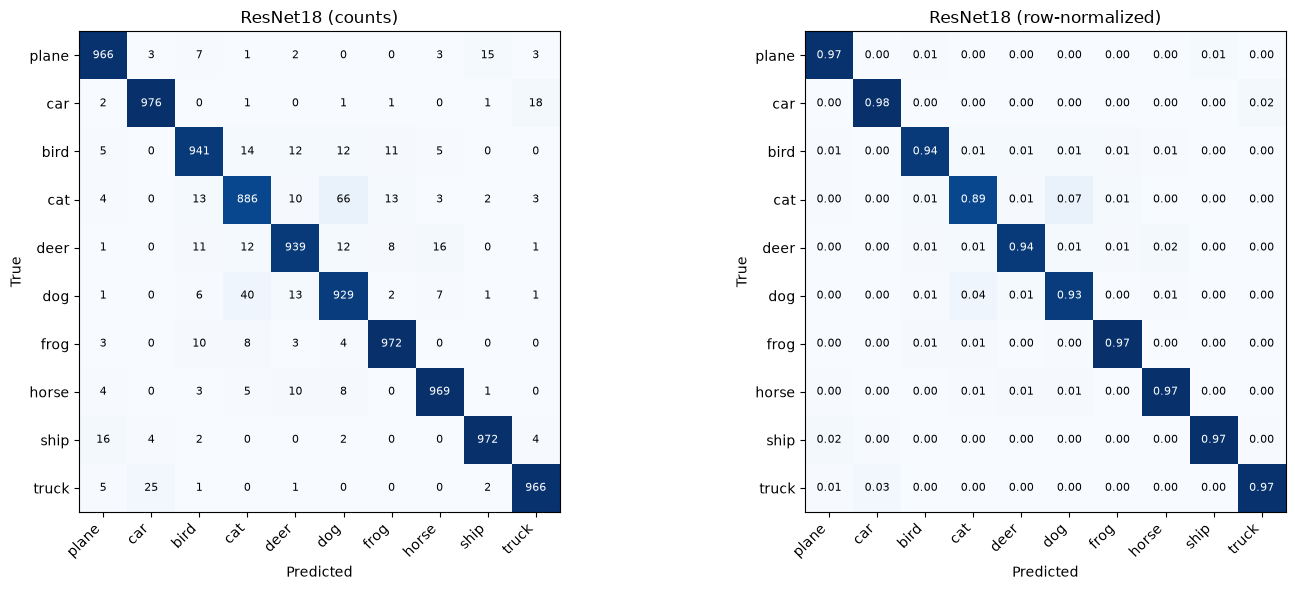

In [35]:
cm_resnet = plot_confusion(y_test, resnet_pred, 'ResNet18')

### B4.5) Per-class metrics, most-confused pairs, misclassified examples

,precision,recall,f1,support
plane,0.9593,0.966,0.9626,1000
car,0.9683,0.976,0.9721,1000
bird,0.9467,0.941,0.9438,1000
cat,0.9162,0.886,0.9009,1000
deer,0.9485,0.939,0.9437,1000
dog,0.8985,0.929,0.9135,1000
frog,0.9652,0.972,0.9686,1000
horse,0.9661,0.969,0.9675,1000
ship,0.9779,0.972,0.9749,1000
truck,0.9699,0.966,0.9679,1000


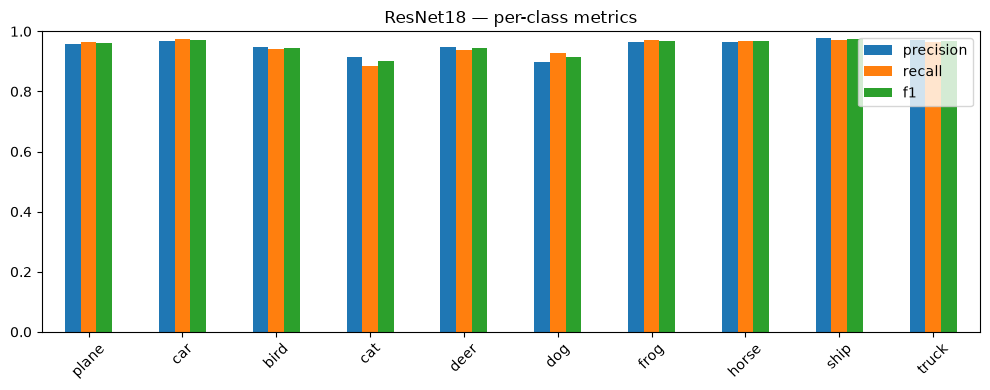

Most confused pairs (true -> predicted):
  cat    -> dog    : 66 images
  dog    -> cat    : 40 images
  truck  -> car    : 25 images
  car    -> truck  : 18 images
  ship   -> plane  : 16 images


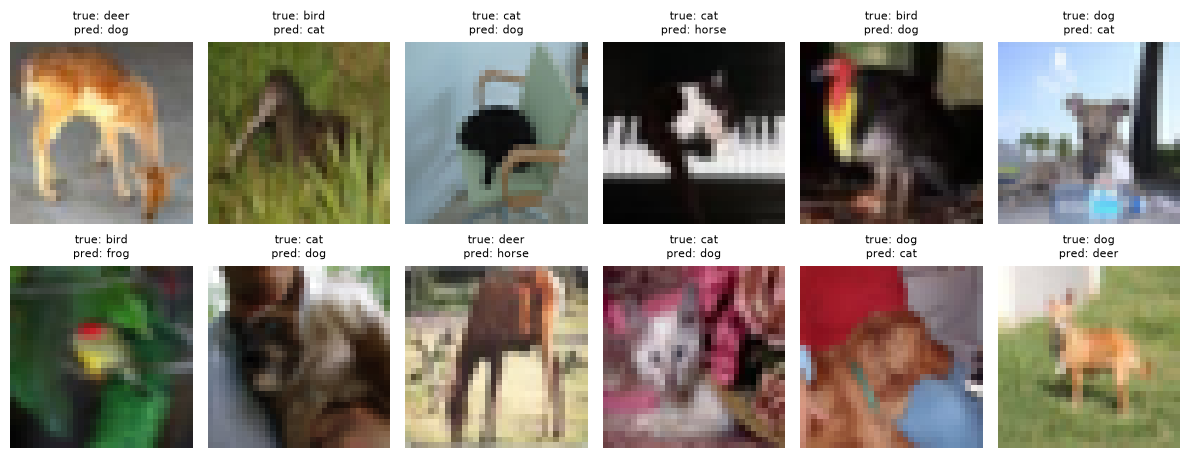

In [36]:
resnet_pc = per_class_table(y_test, resnet_pred)
display(resnet_pc.round(4))

resnet_pc[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 4), title='ResNet18 — per-class metrics')
plt.ylim(0, 1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

off = cm_resnet.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel())[:5], off.shape))[0]
print('Most confused pairs (true -> predicted):')
for i, j in top:
    print('  %-6s -> %-6s : %d images' % (CLASSES[i], CLASSES[j], off[i, j]))

show_misclassified(y_test, resnet_pred)

### B4.6) Save artifacts

Finally, we save the post-training parameters and the class names used in the training.

In [37]:
torch.save(model.state_dict(), OUT_DIR / 'resnet18_cifar10.pt')
with open(OUT_DIR / 'class_names.json', 'w', encoding='utf-8') as f:
    json.dump(CLASSES, f)
print('Saved:', OUT_DIR / 'resnet18_cifar10.pt')
print('Saved:', OUT_DIR / 'class_names.json')

Saved: models\resnet18_cifar10.pt
Saved: models\class_names.json


### B4.7) Package the Part B result

In this section, we save the training results of the model into `resnet_result` for evaluation against the Part A result metrics.

In [38]:
resnet_result = {
    'detail': 'ResNet18 %s, %dpx, %d+%d epochs' %
              ('pretrained' if USE_PRETRAINED else 'from scratch', IMG_SIZE, EPOCHS_1, EPOCHS_2),
    'train_time_s': float(resnet_train_time),
    'metrics': resnet_metrics,
    'per_class': resnet_pc,
    'y_true': np.array(y_test),
    'y_pred': np.array(resnet_pred),
}
print('Part B done:', resnet_result['detail'], '| test accuracy %.4f' % resnet_metrics['accuracy'])

Part B done: ResNet18 pretrained, 128px, 3+7 epochs | test accuracy 0.9516


---
# PART C — Compare

We will compare best of the first train (without ResNet) and best of the second train (with ResNet). Both models are scored on the **same 10,000 test images** with the same metric code.

- First train: the best PCA + SVM setting chosen on the validation set (section A3.2).
- Second train: the best ResNet18 checkpoint chosen on the validation set (section B3).

Part C only uses `svm_result` (from Part A) and `resnet_result` (from Part B), so run both parts first.

## C1. Collect the two results

In [39]:
results = {'PCA+SVM': svm_result, 'ResNet18': resnet_result}

# both models must have been scored on the same test images in the same order
assert (results['PCA+SVM']['y_true'] == results['ResNet18']['y_true']).all()
y_cmp = results['PCA+SVM']['y_true']
print('Comparing:', list(results), '| test images:', len(y_cmp))

Comparing: ['PCA+SVM', 'ResNet18'] | test images: 10000


## C2. Summary table

In [40]:
summary = pd.DataFrame({
    name: {'setup': r['detail'],
           'accuracy': r['metrics']['accuracy'],
           'precision (macro)': r['metrics']['precision_macro'],
           'recall (macro)': r['metrics']['recall_macro'],
           'F1 (macro)': r['metrics']['f1_macro'],
           'train time (min)': r['train_time_s'] / 60}
    for name, r in results.items()
}).T
for c in summary.columns[1:]:
    summary[c] = summary[c].astype(float).round(4)
display(summary)

acc_svm = results['PCA+SVM']['metrics']['accuracy']
acc_res = results['ResNet18']['metrics']['accuracy']
gain = acc_res - acc_svm
winner = 'ResNet18' if gain > 0 else 'PCA+SVM'
print('Test accuracy: PCA+SVM %.2f%%  vs  ResNet18 %.2f%%  ->  %s wins by %.2f points' %
      (100 * acc_svm, 100 * acc_res, winner, 100 * abs(gain)))

,setup,accuracy,precision (macro),recall (macro),F1 (macro),train time (min)
PCA+SVM,PCA(100) + RBF-SVM(C=1.0),0.4994,0.4980,0.4994,0.4975,0.3992
ResNet18,"ResNet18 pretrained, 128px, 3+7 epochs",0.9516,0.9516,0.9516,0.9516,9.5423


Test accuracy: PCA+SVM 49.94%  vs  ResNet18 95.16%  ->  ResNet18 wins by 45.22 points


## C3. Overall metrics side by side

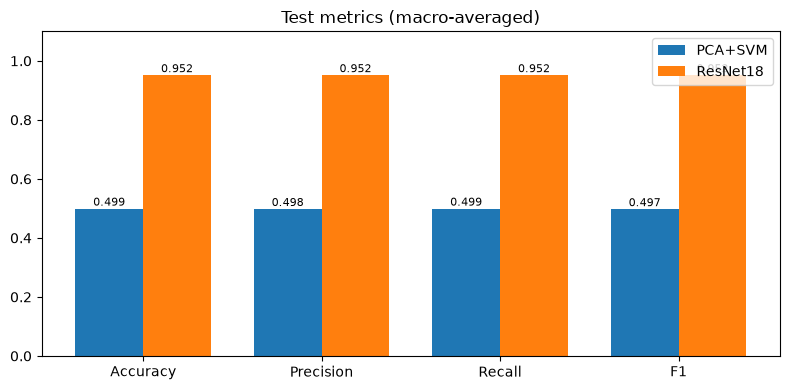

In [41]:
metric_keys = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1']
x = np.arange(len(metric_keys)); w = 0.38

plt.figure(figsize=(8, 4))
for off_i, name in enumerate(results):
    vals = [results[name]['metrics'][k] for k in metric_keys]
    bars = plt.bar(x + (off_i - 0.5) * w, vals, w, label=name)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.01, '%.3f' % v, ha='center', fontsize=8)
plt.xticks(x, metric_labels); plt.ylim(0, 1.1)
plt.title('Test metrics (macro-averaged)'); plt.legend()
plt.tight_layout(); plt.show()

## C4. Per-class F1 and confusion matrices

,PCA+SVM,ResNet18,improvement
plane,0.5800,0.9626,0.3826
car,0.6052,0.9721,0.3669
bird,0.3631,0.9438,0.5808
cat,0.3384,0.9009,0.5624
deer,0.4243,0.9437,0.5194
dog,0.4201,0.9135,0.4934
frog,0.5435,0.9686,0.4251
horse,0.5331,0.9675,0.4344
ship,0.6121,0.9749,0.3628
truck,0.5546,0.9679,0.4133


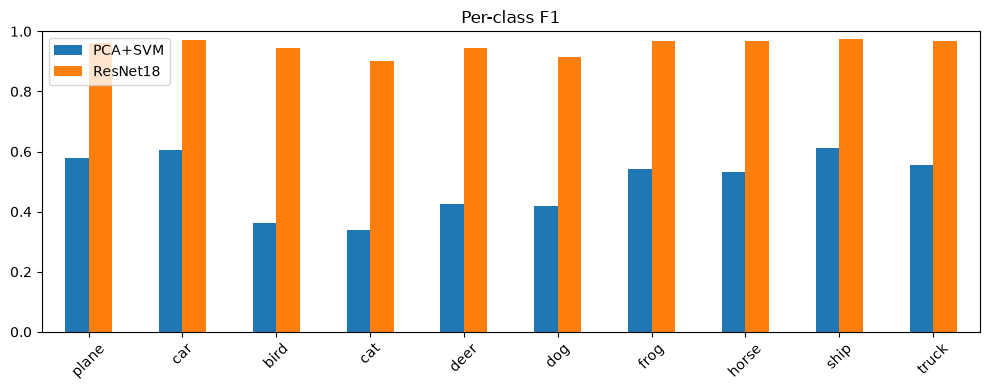

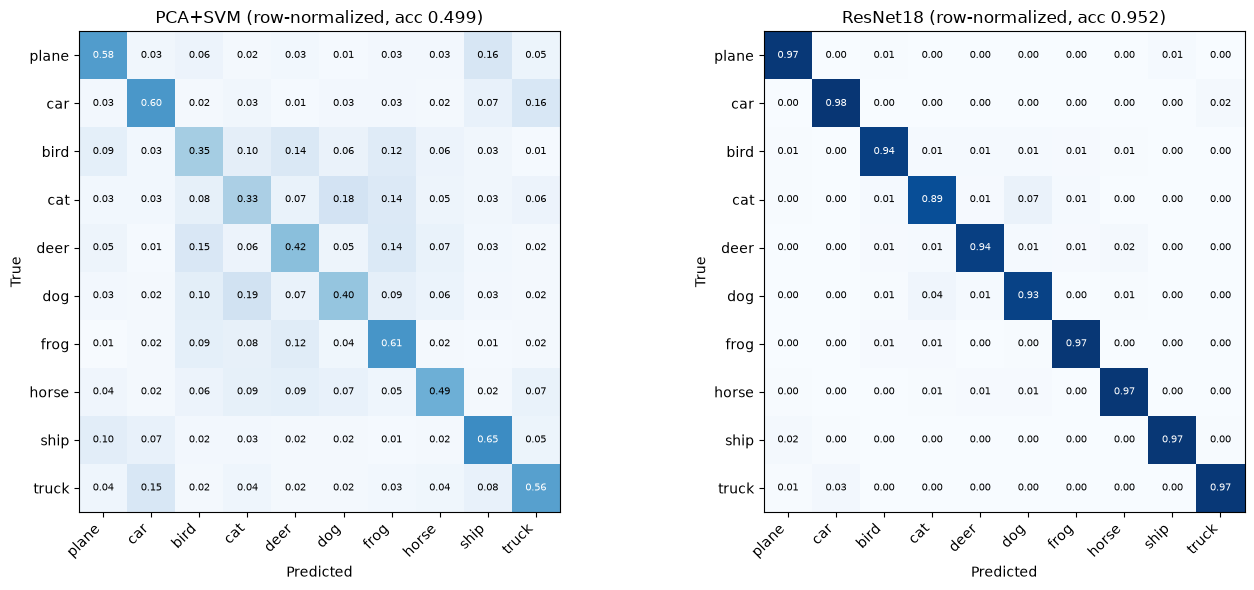

Biggest F1 gain from ResNet18: bird (+0.581)
Smallest F1 gain             : ship (+0.363)


In [42]:
f1_cmp = pd.DataFrame({'PCA+SVM': results['PCA+SVM']['per_class']['f1'],
                       'ResNet18': results['ResNet18']['per_class']['f1']})
f1_cmp['improvement'] = f1_cmp['ResNet18'] - f1_cmp['PCA+SVM']
display(f1_cmp.round(4))

f1_cmp[['PCA+SVM', 'ResNet18']].plot(kind='bar', figsize=(10, 4), title='Per-class F1')
plt.ylim(0, 1); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, results):
    cm = confusion_matrix(y_cmp, results[name]['y_pred'], labels=range(NUM_CLASSES))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_title('%s (row-normalized, acc %.3f)' % (name, results[name]['metrics']['accuracy']))
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASSES, rotation=45, ha='right')
    ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, '%.2f' % cmn[i, j], ha='center', va='center', fontsize=7,
                    color='white' if cmn[i, j] > 0.5 else 'black')
plt.tight_layout(); plt.show()

best_gain = f1_cmp['improvement'].idxmax()
least_gain = f1_cmp['improvement'].idxmin()
print('Biggest F1 gain from ResNet18: %s (%+.3f)' % (best_gain, f1_cmp.loc[best_gain, 'improvement']))
print('Smallest F1 gain             : %s (%+.3f)' % (least_gain, f1_cmp.loc[least_gain, 'improvement']))